# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [7]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.1.3
Pandas version: 2.2.3
Matplotlib version: 3.10.0
Seaborn version: 0.13.2


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [8]:
# Write your code here

#S = ...
S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
#theta = ...
theta = np.array([0.3, 0.7])
#bias = ...
bias = 0.5

# 1. Compute linear combination z
#z = ...
z = S @ theta + bias
print(z)    # [6.3 1.8 4.7 2.2] -> first value is 6.3 

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5) 
#probabilities = ...
probabilities = 1 / (1 + np.exp(-z))
print(probabilities)   # ~[0.998 0.858 0.991 0.900]

# Identify predicted spam emails 
#predicted_spam = ...
predicted_spam = probabilities >= 0.5
print(predicted_spam)  # [ True  True  True  True]

[6.3 1.8 4.7 2.2]
[0.99816706 0.85814894 0.9909867  0.90024951]
[ True  True  True  True]


In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities) 
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [9]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [10]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"
# Write your code here
idx = rng.choice(n, size=12, replace=False)
log.loc[idx, "failed_attempts"] = rng.integers(5, 11, size=12)


In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [11]:
# Insert 10 missing values randomly

# Write your code here
miss_idx = rng.choice(n, size=10, replace=False)
log.loc[miss_idx, "duration_min"] = np.nan

In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [12]:
# Write your code here
ru_log_at_least_five_attempts = len(log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)])


# ru_log_at_least_five_attempts = ...
print(ru_log_at_least_five_attempts)

1


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [13]:
# Write your code here
user_max_failed_attempts = log.groupby("user")["failed_attempts"].sum().sort_values(ascending=False).index[0]


# user_max_failed_attempts = 
print(user_max_failed_attempts)

karim


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [14]:
# Write your code here
# log['long_session'] = ...
log["long_session"] = (log["duration_min"] > 30).astype(int)

In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

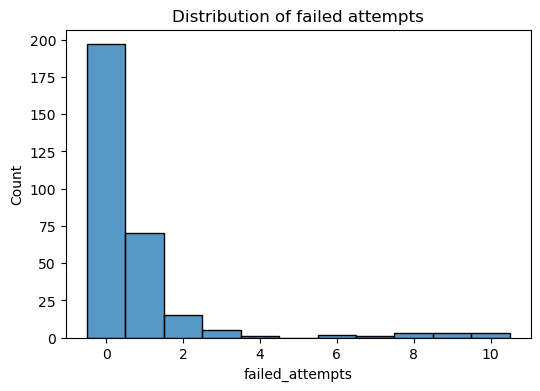

In [15]:
# Draw the histogram of failed_attempts.
# Write your code here
plt.figure(figsize=(6, 4))
sns.histplot(log["failed_attempts"], bins=range(0, 12), discrete=True)
plt.xlabel("failed_attempts"); plt.title("Distribution of failed attempts")
plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [18]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [16]:
# Write your code here
# answer_q2 = ...
answer_q2 = "B"

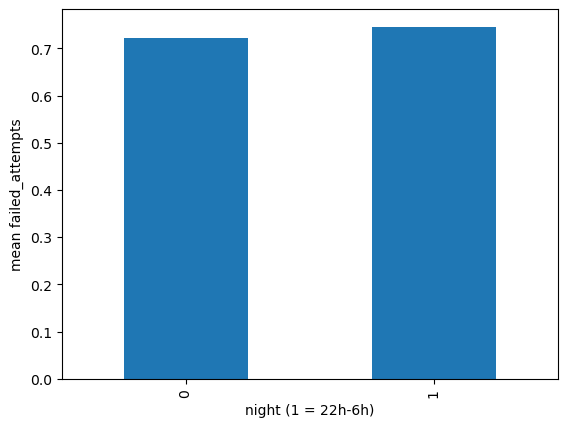

In [17]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
log["night"] = ((log["hour"] >= 22) | (log["hour"] < 6)).astype(int)

log.groupby("night")["failed_attempts"].mean().plot(kind="bar")
plt.xlabel("night (1 = 22h-6h)")
plt.ylabel("mean failed_attempts")
plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code

# X has 300 samples (rows) and 4 features (columns).
# X[:, 2] returns the third feature (column index 2) for all 300 samples, a 1-D array of shape (300,).

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [23]:
# Write your code here
df = log
df.isna().sum()

user               0
hour               0
failed_attempts    0
country            0
duration_min       0
long_session       0
night              0
dtype: int64

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

<Axes: xlabel='country', ylabel='failed_attempts'>

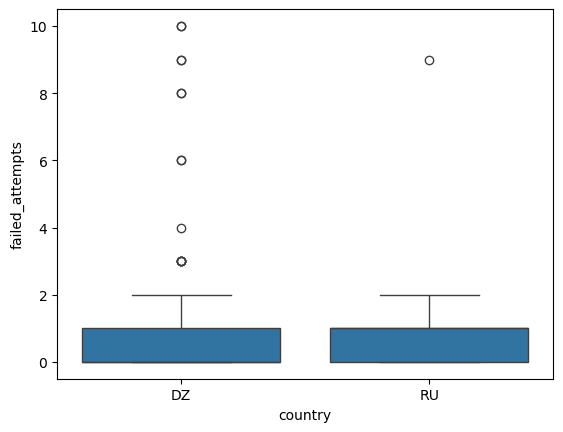

In [19]:
# Write your code here
sns.boxplot(data=log[log["country"].isin(["RU", "DZ"])], x="country", y="failed_attempts")

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
# We scale features so they share the same range and no large-valued feature dominates the others during training.

Commit the logins_clean.csv.(0.5 point)

In [20]:
# save the cleaned table in login_clean.csv
# Write your code here
log["duration_min"] = log["duration_min"].fillna(log["duration_min"].median())
log["long_session"] = (log["duration_min"] > 30).astype(int)  # recompute after filling
log.to_csv("logins_clean.csv", index=False)


In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [21]:
log["duration_min"] = log["duration_min"].fillna(log["duration_min"].median())
log["night"] = ((log["hour"] >= 22) | (log["hour"] < 6)).astype(int)
log.to_csv("logins_clean.csv", index=False)   # the filename is logins_clean.csv, not login_clean.csv as the comment says

df = pd.read_csv("logins_clean.csv")
cols = ["hour", "failed_attempts", "duration_min", "night"]
X = df[cols].to_numpy(dtype=float)
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)
print(X_scaled.shape)   # (300, 4)

(300, 4)


In [22]:
import numpy as np
import pandas as pd
